# Stress test: усиленная label-flip атака

Ноутбук сравнивает чистый сценарий с намеренно жёсткой data-poisoning атакой: **80% клиентов** изменяют **100% доступных меток класса 1 на 7**. Это stress test для наглядной демонстрации чувствительности стенда, а не реалистичная оценка типичной угрозы.

## 1. Конфигурация

Контрольный и атакованный запуски различаются только параметрами атаки. Разбиение, модель, стратегия и seed совпадают.

In [1]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import Markdown, display
except ImportError:
    Markdown = str
    def display(value):
        return value

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pyproject.toml').exists():
    PROJECT_ROOT = next(path for path in [PROJECT_ROOT, *PROJECT_ROOT.parents] if (path / 'pyproject.toml').exists())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from fl_benchmark.attacks.label_flip import build_label_flip_plan
from fl_benchmark.config import load_config
from fl_benchmark.datasets.loader import load_datasets
from fl_benchmark.datasets.partitioning import create_partitions, get_targets
from fl_benchmark.datasets.statistics import compute_partition_statistics
from fl_benchmark.task import run_local_simulation

NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / 'notebooks' / 'results'
NOTEBOOK_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
base_config = load_config(PROJECT_ROOT / 'configs' / 'mnist_strong_label_flip.toml')
clean_config = replace(base_config, name='mnist-strong-label-flip-clean-control', attack=replace(base_config.attack, enabled=False, type='none', malicious_fraction=0.0, poison_fraction=0.0), tracking=replace(base_config.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name='mnist-strong-label-flip-clean-control'), source_path=None)
attack_config = replace(base_config, name='mnist-strong-label-flip-attack', tracking=replace(base_config.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name='mnist-strong-label-flip-attack'), source_path=None)
display(pd.DataFrame([
    ('Датасет / модель / стратегия', f'{base_config.dataset.name} / {base_config.model.name} / {base_config.strategy.name}'),
    ('Клиенты / раунды', f'{base_config.partition.num_clients} / {base_config.federation.num_rounds}'),
    ('Non-IID режим', f'{base_config.partition.type}, alpha={base_config.partition.alpha}'),
    ('Атака', f'{attack_config.attack.source_label} → {attack_config.attack.target_label}'),
    ('Доля вредоносных клиентов', f'{attack_config.attack.malicious_fraction:.0%}'),
    ('Доля изменяемых исходных меток', f'{attack_config.attack.poison_fraction:.0%}'),
], columns=['Параметр', 'Значение']))

,Параметр,Значение
0,Датасет / модель / стратегия,mnist / mnist-cnn / fedavg
1,Клиенты / раунды,10 / 5
2,Non-IID режим,"dirichlet, alpha=0.5"
3,Атака,1 → 7
4,Доля вредоносных клиентов,80%
5,Доля изменяемых исходных меток,100%


## 2. Non-IID-разбиение и масштаб атаки

,client_id,роль,num_examples,entropy,js_divergence,изменено меток
0,0,вредоносный,5669,2.763039,0.149579,1510
1,1,честный,6558,1.947109,0.340865,0
2,2,вредоносный,5193,2.805736,0.126478,438
3,3,вредоносный,9858,2.701288,0.161481,2598
4,4,вредоносный,4116,2.853040,0.141588,53
5,5,честный,4606,2.929246,0.102907,0
6,6,вредоносный,10756,2.579138,0.205664,109
7,7,вредоносный,3576,2.136336,0.290717,883
8,8,вредоносный,5684,2.637645,0.195135,97
9,9,вредоносный,3984,2.290201,0.263737,677


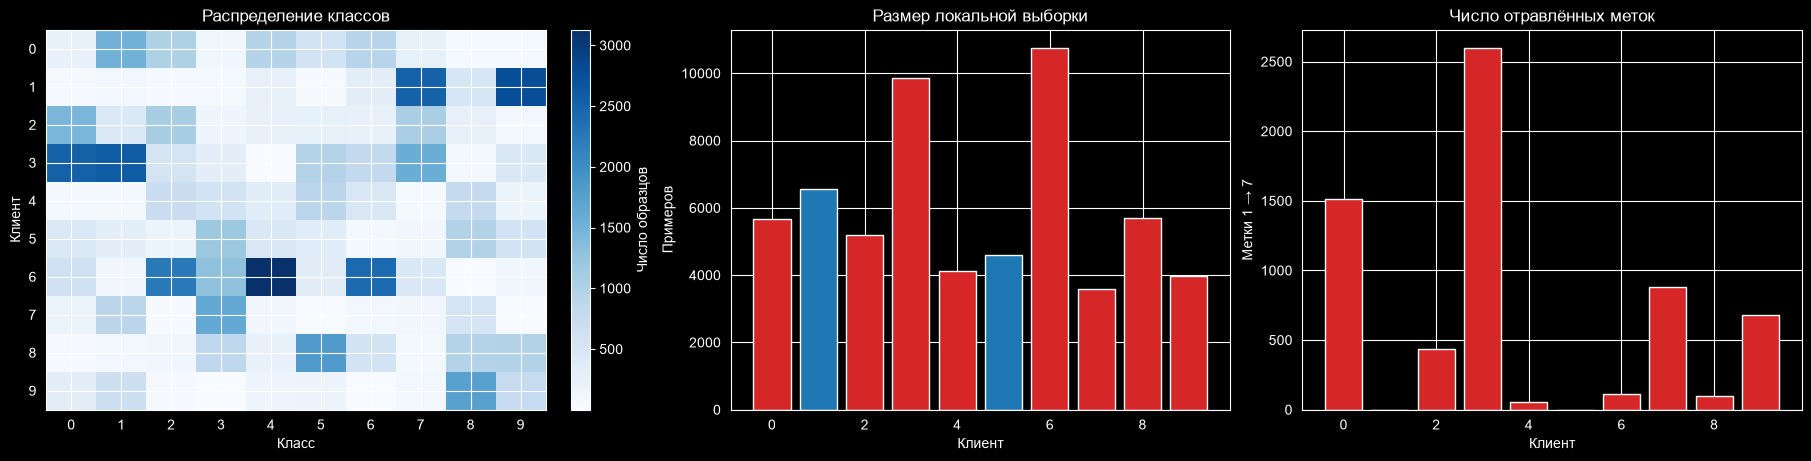

In [2]:
bundle = load_datasets(attack_config.dataset)
targets = get_targets(bundle.train)
partitions = create_partitions(bundle.train, attack_config.partition)
partition_stats = compute_partition_statistics(targets, partitions, attack_config.model.num_classes)
attack_plan = build_label_flip_plan(targets, partitions, attack_config.attack)
stats = partition_stats.statistics.copy().sort_values('client_id')
stats['роль'] = np.where(stats['client_id'].isin(attack_plan.malicious_clients), 'вредоносный', 'честный')
stats['изменено меток'] = [len(attack_plan.poisoned_indices.get(client_id, ())) for client_id in stats['client_id']]
display(stats[['client_id', 'роль', 'num_examples', 'entropy', 'js_divergence', 'изменено меток']])

matrix = partition_stats.matrix.set_index('client_id')
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), constrained_layout=True)
image = axes[0].imshow(matrix.to_numpy(), aspect='auto', cmap='Blues')
axes[0].set(title='Распределение классов', xlabel='Класс', ylabel='Клиент', xticks=range(10), yticks=range(len(matrix)))
fig.colorbar(image, ax=axes[0], label='Число образцов')
colors = np.where(stats['роль'].eq('вредоносный'), 'tab:red', 'tab:blue')
axes[1].bar(stats['client_id'], stats['num_examples'], color=colors)
axes[1].set(title='Размер локальной выборки', xlabel='Клиент', ylabel='Примеров')
axes[2].bar(stats['client_id'], stats['изменено меток'], color=colors)
axes[2].set(title='Число отравлённых меток', xlabel='Клиент', ylabel='Метки 1 → 7')
plt.show()

## 3. Реализованный план атаки
Все доступные у выбранных клиентов примеры класса 1 получают целевую метку 7. Исходный датасет не изменяется: подмена выполняется только в локальной обёртке выборки.

{
  "enabled": true,
  "type": "label_flip",
  "seed": 42,
  "malicious_fraction": 0.8,
  "poison_fraction": 1.0,
  "source_label": 1,
  "target_label": 7,
  "label_flips": [
    {
      "source_label": 1,
      "target_label": 7
    }
  ],
  "malicious_clients": [
    0,
    2,
    3,
    4,
    6,
    7,
    8,
    9
  ],
  "num_malicious_clients": 8,
  "poisoned_examples_per_client": {
    "0": 1510,
    "2": 438,
    "3": 2598,
    "4": 53,
    "6": 109,
    "7": 883,
    "8": 97,
    "9": 677
  },
  "total_poisoned_examples": 6365,
  "poisoned_examples_by_flip": {
    "1->7": 6365
  }
}


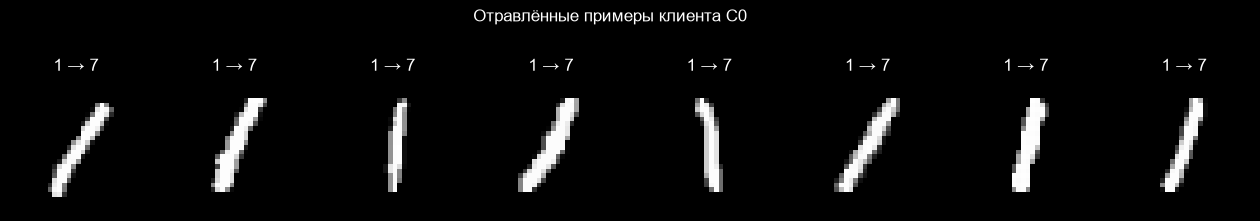

In [3]:
manifest = attack_plan.manifest()
print(json.dumps({key: value for key, value in manifest.items() if key != 'poisoned_indices'}, ensure_ascii=False, indent=2))
client_id = attack_plan.malicious_clients[0]
shown_indices = attack_plan.poisoned_indices[client_id][:8]
fig, axes = plt.subplots(1, len(shown_indices), figsize=(2 * len(shown_indices), 2.8), squeeze=False)
for axis, sample_index in zip(axes[0], shown_indices, strict=True):
    image, true_label = bundle.train[sample_index]
    axis.imshow(image.squeeze(), cmap='gray')
    axis.set_title(f'{true_label} → {attack_config.attack.target_label}')
    axis.axis('off')
fig.suptitle(f'Отравлённые примеры клиента C{client_id}')
plt.show()

## 4. Полный парный запуск
На CPU два полных запуска MNIST могут занять несколько минут. Результаты сохраняются в `notebooks/results/` в отдельных каталогах.

In [4]:
RUN_FULL_EXPERIMENTS = True
if RUN_FULL_EXPERIMENTS:
    clean_output_dir = run_local_simulation(clean_config)
    attack_output_dir = run_local_simulation(attack_config)
    print(f'Контроль: {clean_output_dir}\nАтака: {attack_output_dir}')
else:
    def latest_result(prefix):
        matches = sorted(NOTEBOOK_RESULTS_DIR.glob(f'{prefix}-*'), key=lambda path: path.stat().st_mtime)
        if not matches:
            raise FileNotFoundError(f'Не найдены результаты {prefix!r}')
        return matches[-1]
    clean_output_dir = latest_result('mnist-strong-label-flip-clean-control')
    attack_output_dir = latest_result('mnist-strong-label-flip-attack')

Контроль: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-strong-label-flip-clean-control-20261124-191742-f44511e1
Атака: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-strong-label-flip-attack-20261124-192018-297333e5


## 5. Сравнение глобальных и поклассовых метрик

,Метрика,Контроль,Усиленная атака
0,Итоговая accuracy,0.973100,0.862000
1,Итоговый loss,0.085004,0.978795
2,Macro F1,0.972849,0.840727


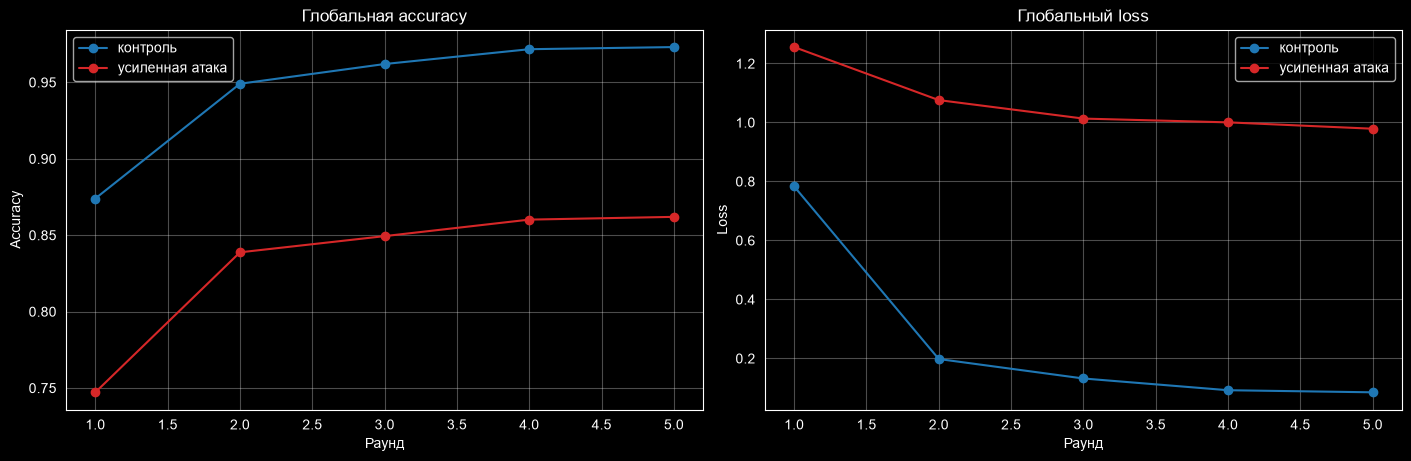

In [5]:
def load_run(output_dir):
    confusion = pd.read_csv(output_dir / 'final_confusion_matrix.csv').to_numpy()
    per_class_path = output_dir / 'final_per_class_metrics.csv'
    if per_class_path.exists():
        per_class = pd.read_csv(per_class_path)
    else:
        support = confusion.sum(axis=1)
        per_class = pd.DataFrame({'class_id': np.arange(len(support)), 'support': support, 'accuracy': np.divide(np.diag(confusion), support, out=np.zeros_like(support, dtype=float), where=support != 0), 'loss': np.nan})
    return {'summary': json.loads((output_dir / 'summary.json').read_text(encoding='utf-8')), 'rounds': pd.read_csv(output_dir / 'round_metrics.csv'), 'clients': pd.read_csv(output_dir / 'client_metrics.csv'), 'per_class': per_class, 'manifest': json.loads((output_dir / 'attack_manifest.json').read_text(encoding='utf-8'))}

clean_run, attack_run = load_run(clean_output_dir), load_run(attack_output_dir)
display(pd.DataFrame([
    ('Итоговая accuracy', clean_run['summary']['final_accuracy'], attack_run['summary']['final_accuracy']),
    ('Итоговый loss', clean_run['summary']['final_loss'], attack_run['summary']['final_loss']),
    ('Macro F1', clean_run['summary']['final_macro_f1'], attack_run['summary']['final_macro_f1']),
], columns=['Метрика', 'Контроль', 'Усиленная атака']))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for run, label, color in [(clean_run, 'контроль', 'tab:blue'), (attack_run, 'усиленная атака', 'tab:red')]:
    axes[0].plot(run['rounds']['round'], run['rounds']['global_accuracy'], marker='o', label=label, color=color)
    axes[1].plot(run['rounds']['round'], run['rounds']['global_loss'], marker='o', label=label, color=color)
axes[0].set(title='Глобальная accuracy', xlabel='Раунд', ylabel='Accuracy')
axes[1].set(title='Глобальный loss', xlabel='Раунд', ylabel='Loss')
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend()
plt.show()

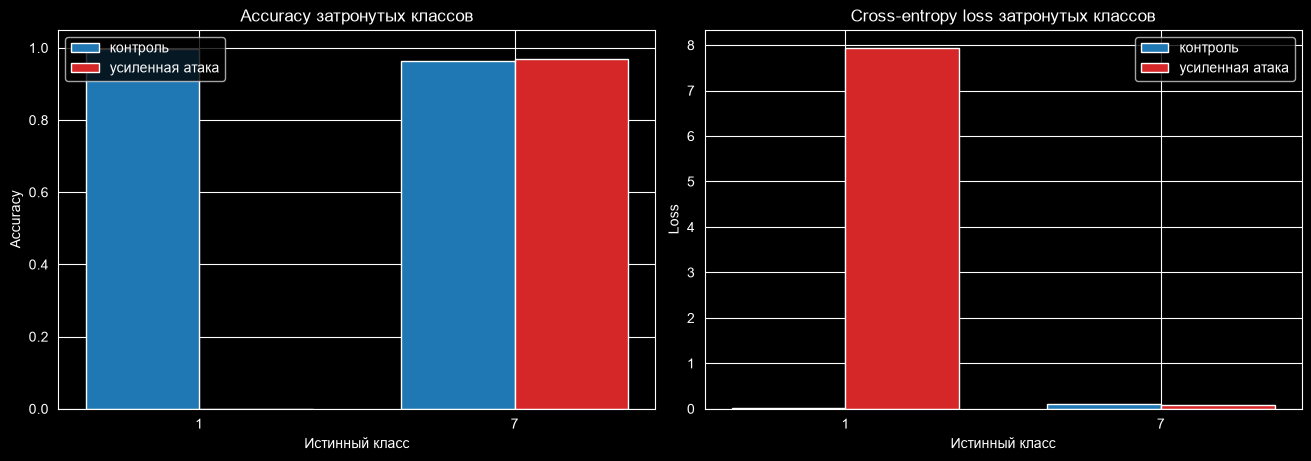

,класс,accuracy: контроль,accuracy: атака,loss: контроль,loss: атака
0,1,0.995595,0.000000,0.022903,7.940203
1,7,0.963035,0.969844,0.094162,0.082998


In [6]:
focus_classes = [attack_config.attack.source_label, attack_config.attack.target_label]
clean_focus = clean_run['per_class'].set_index('class_id').reindex(focus_classes)
attack_focus = attack_run['per_class'].set_index('class_id').reindex(focus_classes)
x, width = np.arange(len(focus_classes)), 0.36
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].bar(x - width / 2, clean_focus['accuracy'], width, label='контроль', color='tab:blue')
axes[0].bar(x + width / 2, attack_focus['accuracy'], width, label='усиленная атака', color='tab:red')
axes[0].set(title='Accuracy затронутых классов', xlabel='Истинный класс', ylabel='Accuracy', xticks=x, xticklabels=focus_classes, ylim=(0, 1.05))
axes[0].legend()
if clean_focus['loss'].isna().any() or attack_focus['loss'].isna().any():
    axes[1].text(0.5, 0.5, 'Нет поклассового loss; перезапустите сценарий.', ha='center', va='center', transform=axes[1].transAxes)
    axes[1].set_axis_off()
else:
    axes[1].bar(x - width / 2, clean_focus['loss'], width, label='контроль', color='tab:blue')
    axes[1].bar(x + width / 2, attack_focus['loss'], width, label='усиленная атака', color='tab:red')
    axes[1].set(title='Cross-entropy loss затронутых классов', xlabel='Истинный класс', ylabel='Loss', xticks=x, xticklabels=focus_classes)
    axes[1].legend()
plt.show()
focus = pd.DataFrame({'класс': focus_classes, 'accuracy: контроль': clean_focus['accuracy'].to_numpy(), 'accuracy: атака': attack_focus['accuracy'].to_numpy(), 'loss: контроль': clean_focus['loss'].to_numpy(), 'loss: атака': attack_focus['loss'].to_numpy()})
display(focus)

## 6. Интерпретация
Этот режим специально завышает ресурсы атакующего. Его назначение — показать предельный эффект label flipping и проверить, какие метрики первыми сигнализируют о деградации. Результаты одного seed остаются демонстрационными.

In [7]:
delta_accuracy = attack_run['summary']['final_accuracy'] - clean_run['summary']['final_accuracy']
delta_loss = attack_run['summary']['final_loss'] - clean_run['summary']['final_loss']
display(Markdown(f'''
### Итог stress test

- Изменено меток: **{attack_run['manifest']['total_poisoned_examples']}**.
- Вредоносных клиентов: **{attack_run['manifest']['num_malicious_clients']} из {attack_config.partition.num_clients}**.
- Изменение global accuracy: **{delta_accuracy:+.4f}**.
- Изменение global loss: **{delta_loss:+.4f}**.

Сценарий является стресс-тестом; его нельзя выдавать за реалистичную распространённость атакующих клиентов.
'''))


### Итог stress test

- Изменено меток: **6365**.
- Вредоносных клиентов: **8 из 10**.
- Изменение global accuracy: **-0.1111**.
- Изменение global loss: **+0.8938**.

Сценарий является стресс-тестом; его нельзя выдавать за реалистичную распространённость атакующих клиентов.
